# Are the task-variance clusters modules? (lesion test)

A silhouette score only says whether neurons fall into groups. This notebook asks whether a group **does a job**:

1. Cluster the neurons by task variance (as before; k = highest local maximum of silhouette with k > 2).
2. **Silence one cluster** (its neurons' activity is held at 0 on every time step) and re-score all 20 tasks.
3. Compare with silencing **random groups with the same number of E and I units**. A cluster is a module if
   silencing it breaks *some* tasks much more than such a random group does.

Networks (all 150k steps, W_out frozen at the fanin init, so they differ only in the budget):

* **control**: no budget (`dale_all_rateray_woutfrozen_150k/control`, seed 1).
* **rate-limited**: rate budget 0.017, wiring free (`dale_all_rateray_woutfrozen_150k/A0`, seed 0).
* **wiring-limited**: wiring budget 0.0054, rate free (`dale_all_wiringray_woutfrozen_150k/B0`, seed 0).

Add a network to `NETS` to study it too.

In [1]:
import contextlib, io
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from cmc.paths import MOO_ZOOM_RUNS_DIR
from cmc.task import generate_trials, rule_name
from cmc.train_cog import (batch_accuracy, eval_config_from, load_checkpoint, response_mask, ring_prefs,
                           trial_to_tensors)

RUN = MOO_ZOOM_RUNS_DIR / "dale_all_rateray_woutfrozen_150k"
NETS = {
    "control": RUN / "control" / "seed_01.pt",
    "rate-limited (A0)": RUN / "A0" / "seed_00.pt",
    "wiring-limited (B0)": MOO_ZOOM_RUNS_DIR / "dale_all_wiringray_woutfrozen_150k" / "B0" / "seed_00.pt",
}
EVAL_SEEDS = (10000, 10001, 10002)   # fixed eval trials (first 3 of the front's 10 eval seeds)
BATCH = 64
N_RANDOM = 5                         # random lesions (same E and I counts) per cluster
SIL_REF = 0.2

## 1. The machinery

* `simulate`: the same update as `model.simulate`, plus one line: after each step the silenced neurons are set to 0. A
  silenced neuron then sends nothing to the others and nothing to the readout, for the whole trial.
* The eval trials are generated once per network and reused for every lesion, so all differences come from the
  lesion alone.
* `study` runs everything for one network: intact accuracy, clusters, each cluster silenced, random lesions.

In [2]:
def simulate(model, x, keep):
    # keep: (N,) tensor, 1 = normal, 0 = silenced
    x = model._normalize_input(x)
    B, _, T = x.shape
    h = torch.zeros(B, model.n_rnn)
    W = model.effective_w_rec()
    out = []
    for t in range(T):
        gate = x[:, :, t] @ model.w_in + h @ W + model.bias
        h = (1 - model.alpha) * h + model.alpha * model._cell_act(gate)
        h = h * keep
        out.append(torch.sigmoid(h[:, :model.n_e] @ model.w_out + model.b_out))
    return torch.stack(out, dim=1)


def cluster_units(tv, N):
    total = tv.sum(0)
    active = total > 1e-2 * total.max()
    norm = tv[:, active] / tv[:, active].max(0, keepdims=True)
    X = norm.T
    sil, labs = {}, {}
    for k in range(2, 21):
        labs[k] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)
        sil[k] = silhouette_score(X, labs[k])
    local = [k for k in range(3, 20) if sil[k] > sil[k - 1] and sil[k] > sil[k + 1]]
    K = max(local, key=sil.get)
    lab = labs[K]
    # order clusters by preferred task so the plots read top-left to bottom-right
    pref = {c: int(np.argmax(norm[:, lab == c].mean(axis=1))) for c in range(K)}
    order = sorted(range(K), key=lambda c: (pref[c], -norm[pref[c], lab == c].mean()))
    cluster = np.full(N, -1)
    cluster[np.flatnonzero(active)] = [order.index(c) for c in lab]
    return active, cluster, K, sil, local


def study(name, ckpt):
    with contextlib.redirect_stdout(io.StringIO()):
        model, config, ck = load_checkpoint(ckpt)
    model.eval()
    tasks = list(ck["active_tasks"])
    N, N_E = model.n_rnn, model.n_e
    trials = {}
    for rule in tasks:
        for s in EVAL_SEEDS:
            cfg = eval_config_from(config, s, easy_task=True)
            tr = generate_trials(rule, cfg, BATCH, noise_on=False)
            x, _, _, y_loc = trial_to_tensors(tr, "cpu")
            trials[rule, s] = (x, y_loc, response_mask(tr, "cpu"), ring_prefs(cfg, "cpu", torch.float32))

    @torch.no_grad()
    def task_acc(keep):
        acc = {}
        for rule in tasks:
            a = [batch_accuracy(simulate(model, x, keep), y_loc, prefs, resp_mask=rmask)["acc"]
                 for x, y_loc, rmask, prefs in (trials[rule, s] for s in EVAL_SEEDS)]
            acc[rule] = float(np.mean(a))
        return pd.Series(acc)

    base = task_acc(torch.ones(N))
    tv = np.asarray(ck["task_variance"], dtype=float)                 # (tasks, units)
    active, cluster, K, sil, local = cluster_units(tv, N)
    is_E = np.arange(N) < N_E
    act_E, act_I = np.flatnonzero(active & is_E), np.flatnonzero(active & ~is_E)
    rng = np.random.default_rng(0)
    drop, rand_drop, rows = {}, {}, []
    for c in range(K):
        members = np.flatnonzero(cluster == c)
        nE, nI = int(is_E[members].sum()), int((~is_E[members]).sum())
        keep = torch.ones(N); keep[members] = 0
        drop[c + 1] = base - task_acc(keep)
        r = []
        for _ in range(N_RANDOM):
            keep = torch.ones(N)
            keep[np.r_[rng.choice(act_E, nE, replace=False), rng.choice(act_I, nI, replace=False)]] = 0
            r.append(base - task_acc(keep))
        rand_drop[c + 1] = pd.concat(r, axis=1).mean(axis=1)
        rows.append(dict(cluster=c + 1, units=len(members), E=nE, I=nI))
    D = pd.DataFrame(drop).T.rename(columns=rule_name)
    RD = pd.DataFrame(rand_drop).T.rename(columns=rule_name)
    info = pd.DataFrame(rows).set_index("cluster")
    summary = info.assign(**{
        "mean drop": D.mean(axis=1), "random mean drop": RD.mean(axis=1),
        "excess over random": D.mean(axis=1) - RD.mean(axis=1),
        "max drop": D.max(axis=1), "worst task": D.idxmax(axis=1),
        "max specific drop": (D - RD).max(axis=1), "on task": (D - RD).idxmax(axis=1),
        "specificity": D.max(axis=1) - D.mean(axis=1)})
    print(f"{name}: {ckpt.relative_to(MOO_ZOOM_RUNS_DIR)} | intact min {base.min():.3f}, mean {base.mean():.3f} | "
          f"{active.sum()} active units, k = {K}, silhouette {sil[K]:.3f} (local maxima {local})")
    return dict(name=name, tasks=tasks, N=N, N_E=N_E, tv=tv, base=base, active=active, cluster=cluster, K=K,
                sil=sil, local=local, D=D, RD=RD, info=info, summary=summary)


def plot_clusters(R):
    tv, cluster, K, N_E = R["tv"], R["cluster"], R["K"], R["N_E"]
    labels = [rule_name[t] for t in R["tasks"]]
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw=dict(width_ratios=[3.2, 1]))
    idx = np.flatnonzero(R["active"])
    idx = idx[np.lexsort((idx >= N_E, cluster[idx]))]
    ax.imshow((tv / np.maximum(tv.max(0, keepdims=True), 1e-30))[:, idx], cmap="hot", aspect="auto",
              interpolation="nearest", vmin=0, vmax=1)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels, fontsize=7); ax.set_xticks([])
    cols = plt.cm.tab20(np.linspace(0, 1, 20))
    for c in range(K):
        pos = np.flatnonzero(cluster[idx] == c)
        ax.plot([pos[0] - .5, pos[-1] + .5], [len(labels) + .4] * 2, lw=5, color=cols[c % 20], clip_on=False,
                solid_capstyle="butt")
        ax.text(pos.mean(), len(labels) + 1.4, str(c + 1), ha="center", va="top", fontsize=7)
    ax.set_ylim(len(labels) - .5, -.5)
    ax.set_title(f"{R['name']}: task variance, units grouped by cluster (k = {K})", fontsize=9)
    sil, local = R["sil"], R["local"]
    ax2.plot(list(sil), list(sil.values()), "o-", ms=3)
    ax2.scatter(local, [sil[k] for k in local], s=60, facecolors="none", edgecolors="orange", label="local maxima")
    ax2.axvline(K, color="orange", ls="--", lw=1); ax2.axhline(SIL_REF, color="k", ls="--", lw=1)
    ax2.set_xlabel("k"); ax2.set_ylabel("silhouette"); ax2.legend(fontsize=7)
    plt.tight_layout(); plt.show()


def lesion_panel(ax, M, info, cmap, lim, title, annotate):
    # tasks on y, clusters on x; each cluster's column is as wide as its number of units (like the TV heatmap)
    edges = np.r_[0, np.cumsum(info.units.values)]
    tasks = list(M.columns)
    im = ax.pcolormesh(edges, np.arange(len(tasks) + 1) - 0.5, M.values.T, cmap=cmap, vmin=lim[0], vmax=lim[1])
    for x in edges[1:-1]:
        ax.axvline(x, color="k", lw=0.6)
    centres = (edges[:-1] + edges[1:]) / 2
    if annotate:
        for j, (c, w) in enumerate(zip(centres, info.units.values)):
            for i, v in enumerate(M.values[j]):
                if abs(v) >= 0.1 and w >= 6:
                    ax.text(c, i, f"{v:.2f}", ha="center", va="center", fontsize=6 if w >= 12 else 5)
    ax.set_yticks(range(len(tasks))); ax.set_yticklabels(tasks, fontsize=7)
    ax.set_ylim(len(tasks) - 0.5, -0.5)
    ax.set_xticks(centres)
    ax.set_xticklabels([f"{c}" for c in info.index], fontsize=7)
    ax.set_xlabel("cluster (column width = number of units)", fontsize=8)
    ax.set_title(title, fontsize=10)
    return im


def plot_lesions(R):
    D, RD, info = R["D"], R["RD"], R["info"]
    vmax = max(0.5, D.values.max())
    # small: the two raw drops
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
    for ax, M, title in [(axes[0], D, "accuracy drop when the cluster is silenced"),
                         (axes[1], RD, f"random lesion, same E and I counts (mean of {N_RANDOM})")]:
        im = lesion_panel(ax, M, info, "Reds", (0, vmax), title, annotate=False)
    fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01, label="accuracy drop")
    fig.suptitle(R["name"], fontsize=11)
    plt.show()
    # big: specific drop
    fig, ax = plt.subplots(figsize=(15, 6.5))
    im = lesion_panel(ax, D - RD, info, "RdBu_r", (-0.5, 0.5),
                      f"{R['name']}: specific drop = cluster silenced − random (same E/I counts); "
                      f"red = the cluster matters for this task more than any group of its size", annotate=True)
    ax.set_xticklabels([f"{c}\n{r.units} u\n{r.E}E {r.I}I" for c, r in info.iterrows()], fontsize=7)
    fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label="specific accuracy drop")
    plt.tight_layout(); plt.show()


RES = {name: study(name, ck) for name, ck in NETS.items()}

control: dale_all_rateray_woutfrozen_150k\control\seed_01.pt | intact min 0.943, mean 0.993 | 248 active units, k = 6, silhouette 0.215 (local maxima [6, 12, 14, 16, 19])


rate-limited (A0): dale_all_rateray_woutfrozen_150k\A0\seed_00.pt | intact min 0.776, mean 0.969 | 237 active units, k = 7, silhouette 0.437 (local maxima [5, 7, 9, 12, 17])


wiring-limited (B0): dale_all_wiringray_woutfrozen_150k\B0\seed_00.pt | intact min 0.745, mean 0.946 | 236 active units, k = 9, silhouette 0.186 (local maxima [7, 9, 12, 17, 19])


## 2. control

Intact accuracy, clusters, then each cluster silenced vs random groups with the same E and I counts.
* **mean drop**: how much silencing the cluster hurts on average.
* **excess over random**: mean drop minus the random lesion's mean drop.
* **max specific drop**: the largest (cluster − random) drop on one task, and which task.
* **specificity**: biggest drop on one task − mean drop over tasks. High = it breaks a few tasks, not all.

,Go,RT Go,Dly Go,Anti,RT Anti,Dly Anti,DM 1,DM 2,Ctx DM 1,Ctx DM 2,MultSen DM,Dly DM 1,Dly DM 2,Ctx Dly DM 1,Ctx Dly DM 2,MultSen Dly DM,DMS,DNMS,DMC,DNMC
intact accuracy,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.99,0.99,0.98,0.97,1.0,0.98,0.94,1.0,1.0


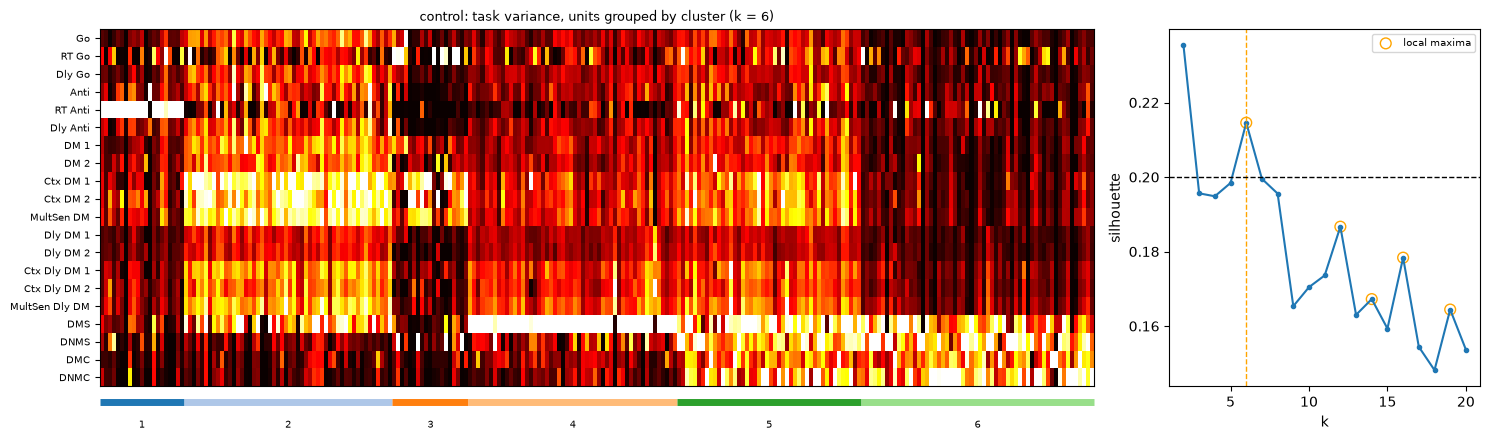

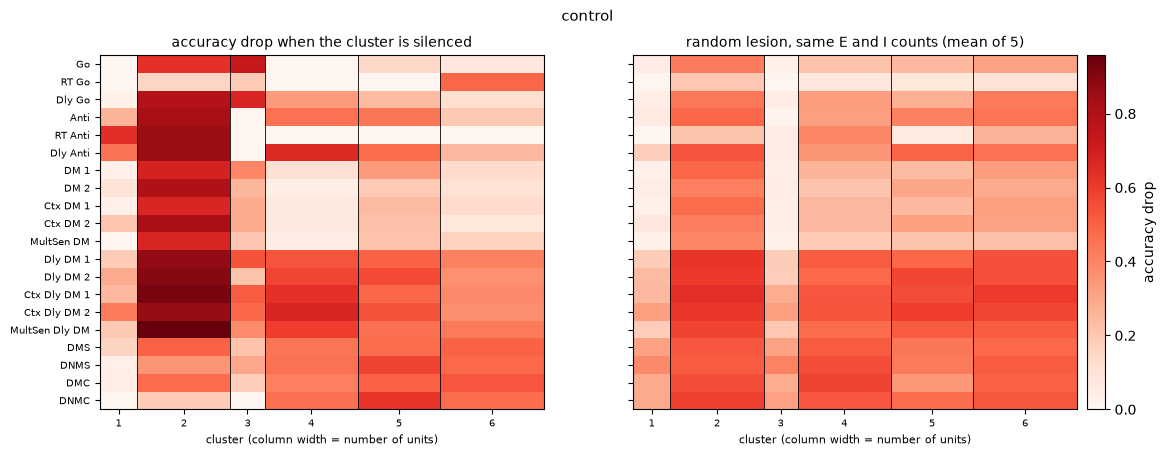

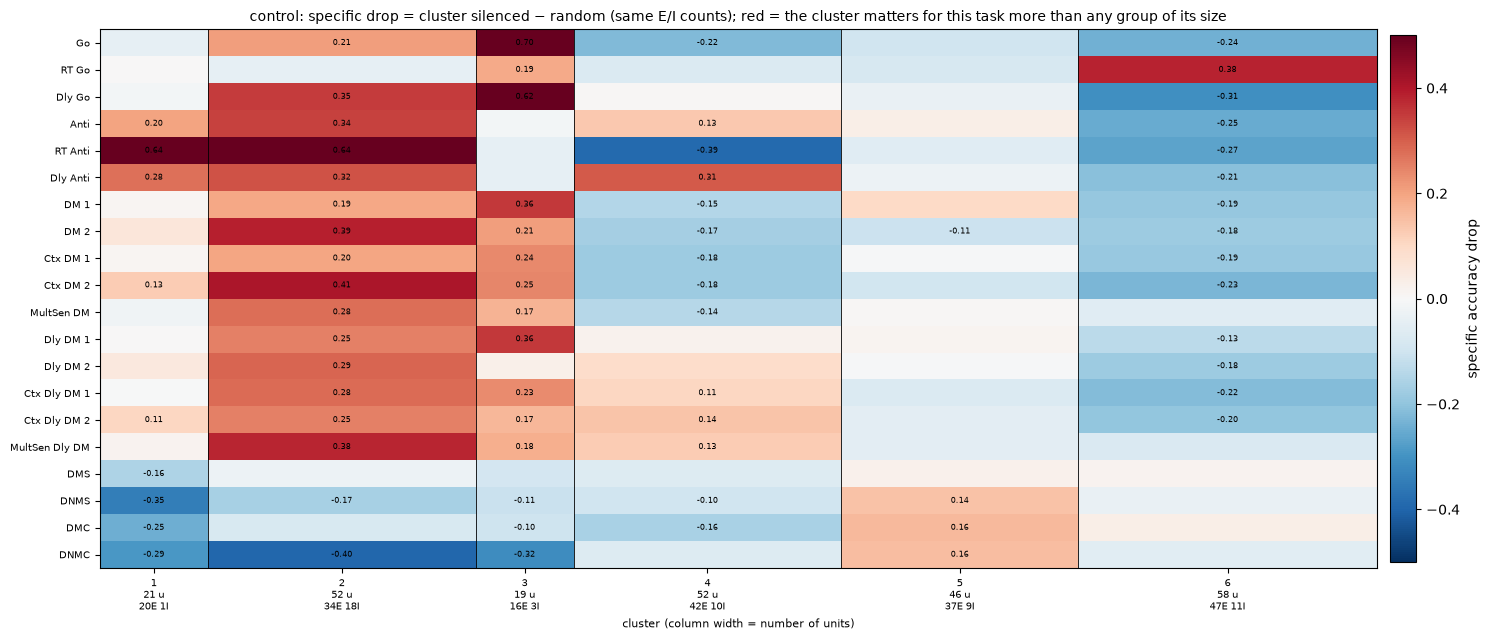

,units,E,I,mean drop,random mean drop,excess over random,max drop,worst task,max specific drop,on task,specificity
cluster,,,,,,,,,,,
1,21,20,1,0.168,0.149,0.019,0.641,RT Anti,0.641,RT Anti,0.472
2,52,34,18,0.690,0.487,0.203,0.958,MultSen Dly DM,0.641,RT Anti,0.268
3,19,16,3,0.293,0.144,0.149,0.734,Go,0.703,Go,0.442
4,52,42,10,0.329,0.378,-0.048,0.677,Ctx Dly DM 2,0.307,Dly Anti,0.348
5,46,37,9,0.362,0.365,-0.003,0.625,DNMC,0.160,DMC,0.263
6,58,47,11,0.286,0.415,-0.130,0.531,DMC,0.383,RT Go,0.246


In [3]:
R = RES["control"]
display(R["base"].rename(index=rule_name).round(2).to_frame("intact accuracy").T)
plot_clusters(R)
plot_lesions(R)
R["summary"].round(3)

## 3. rate-limited (A0)

Intact accuracy, clusters, then each cluster silenced vs random groups with the same E and I counts.
* **mean drop**: how much silencing the cluster hurts on average.
* **excess over random**: mean drop minus the random lesion's mean drop.
* **max specific drop**: the largest (cluster − random) drop on one task, and which task.
* **specificity**: biggest drop on one task − mean drop over tasks. High = it breaks a few tasks, not all.

,Go,RT Go,Dly Go,Anti,RT Anti,Dly Anti,DM 1,DM 2,Ctx DM 1,Ctx DM 2,MultSen DM,Dly DM 1,Dly DM 2,Ctx Dly DM 1,Ctx Dly DM 2,MultSen Dly DM,DMS,DNMS,DMC,DNMC
intact accuracy,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.99,1.0,0.99,0.92,0.96,0.95,0.95,0.9,0.93,0.78,1.0,1.0


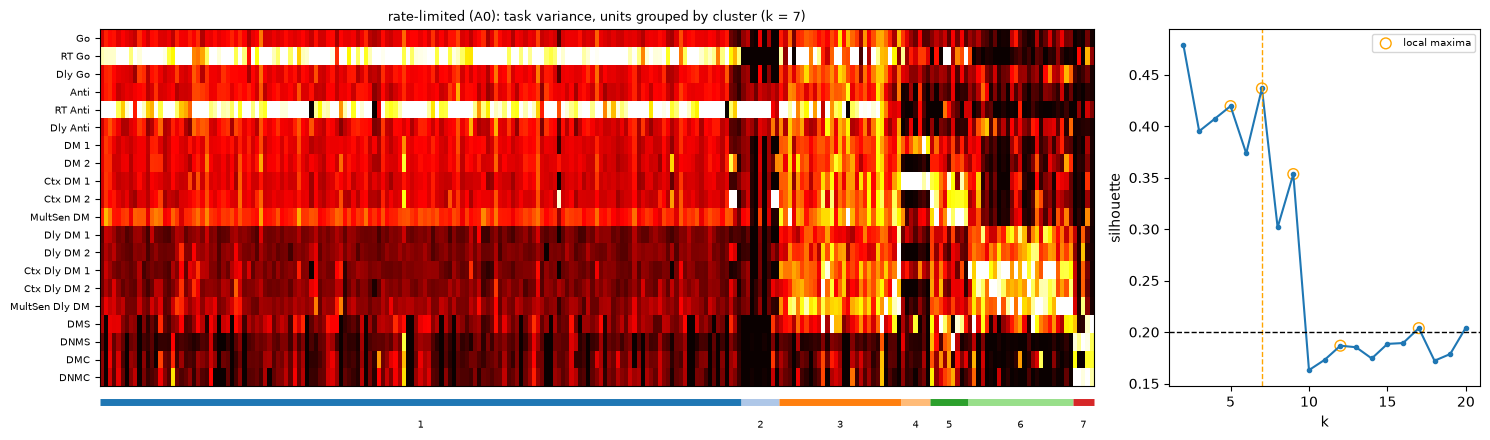

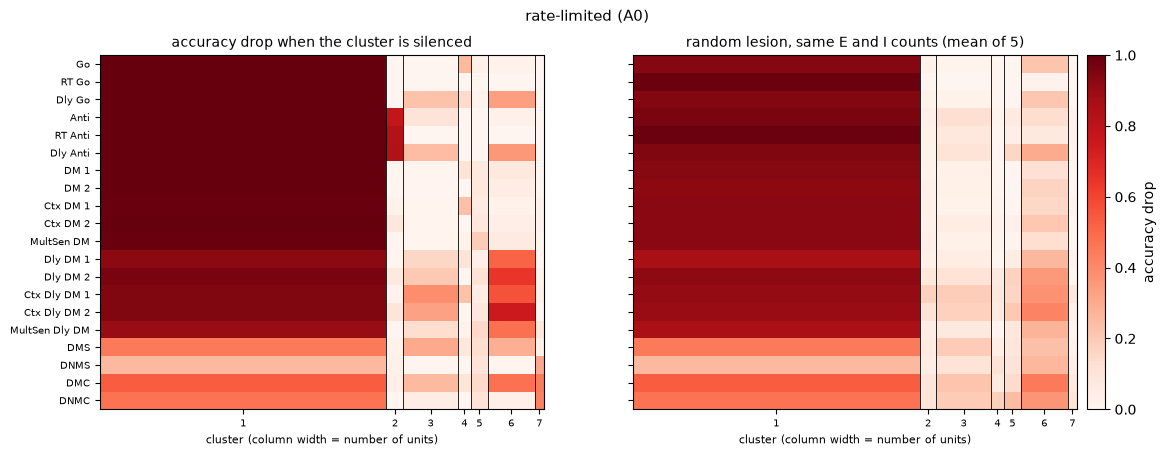

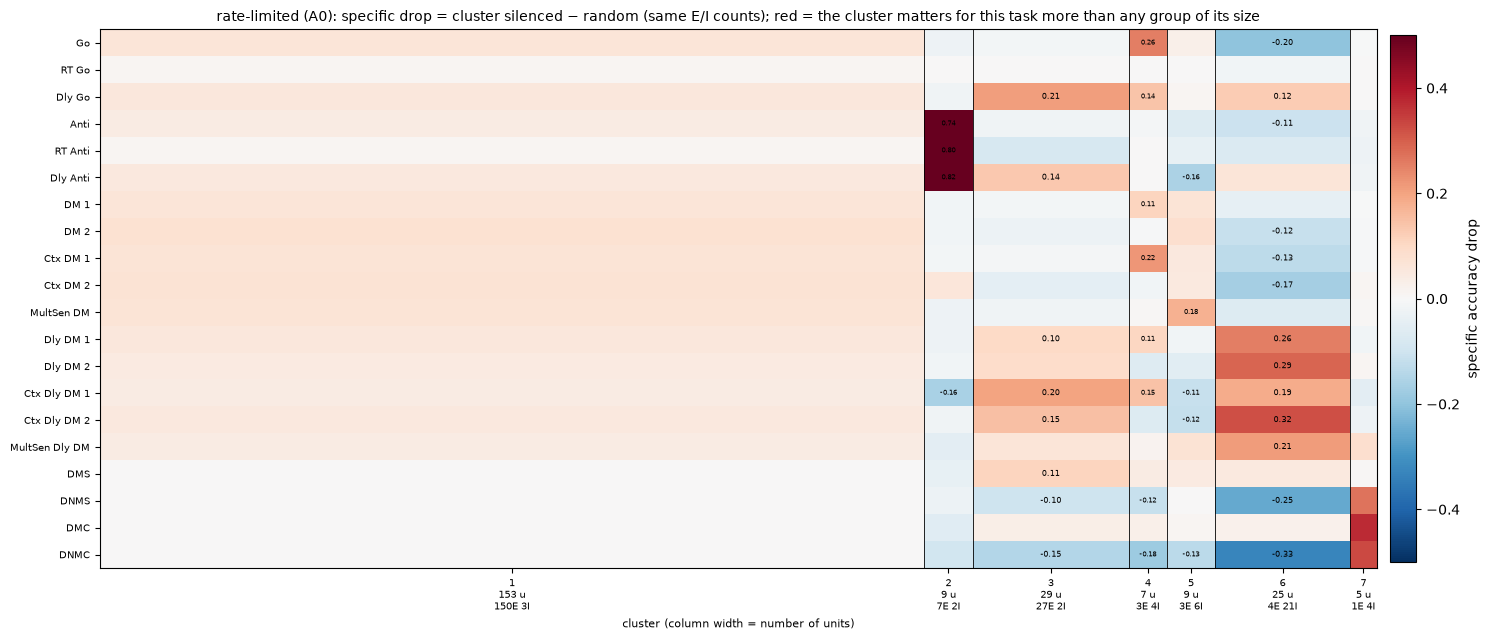

,units,E,I,mean drop,random mean drop,excess over random,max drop,worst task,max specific drop,on task,specificity
cluster,,,,,,,,,,,
1,153,150,3,0.869,0.828,0.041,1.000,Go,0.076,DM 2,0.131
2,9,7,2,0.142,0.052,0.089,0.839,Dly Anti,0.817,Dly Anti,0.697
3,29,27,2,0.123,0.092,0.030,0.391,Ctx Dly DM 1,0.208,Dly Go,0.268
4,7,3,4,0.065,0.034,0.031,0.255,Go,0.255,Go,0.190
5,9,3,6,0.074,0.080,-0.006,0.193,MultSen DM,0.177,MultSen DM,0.119
6,25,4,21,0.238,0.237,0.001,0.745,Ctx Dly DM 2,0.323,Ctx Dly DM 2,0.507
7,5,1,4,0.069,0.024,0.045,0.443,DMC,0.372,DMC,0.373


In [4]:
R = RES["rate-limited (A0)"]
display(R["base"].rename(index=rule_name).round(2).to_frame("intact accuracy").T)
plot_clusters(R)
plot_lesions(R)
R["summary"].round(3)

## 4. wiring-limited (B0)

Intact accuracy, clusters, then each cluster silenced vs random groups with the same E and I counts.
* **mean drop**: how much silencing the cluster hurts on average.
* **excess over random**: mean drop minus the random lesion's mean drop.
* **max specific drop**: the largest (cluster − random) drop on one task, and which task.
* **specificity**: biggest drop on one task − mean drop over tasks. High = it breaks a few tasks, not all.

,Go,RT Go,Dly Go,Anti,RT Anti,Dly Anti,DM 1,DM 2,Ctx DM 1,Ctx DM 2,MultSen DM,Dly DM 1,Dly DM 2,Ctx Dly DM 1,Ctx Dly DM 2,MultSen Dly DM,DMS,DNMS,DMC,DNMC
intact accuracy,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.99,1.0,1.0,1.0,0.94,0.93,0.84,0.74,0.88,0.86,0.75,1.0,0.99


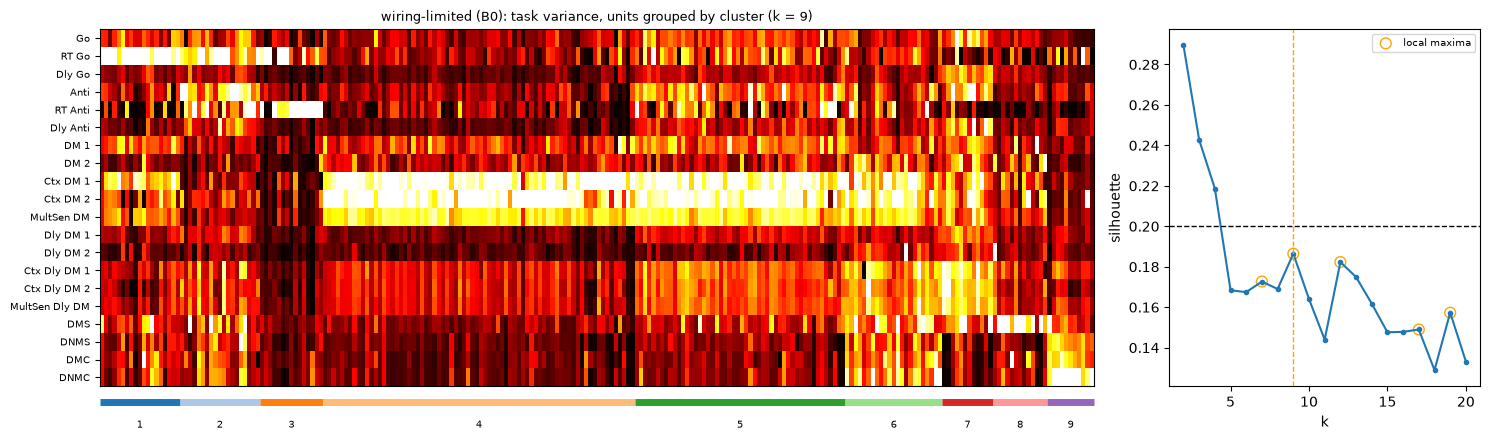

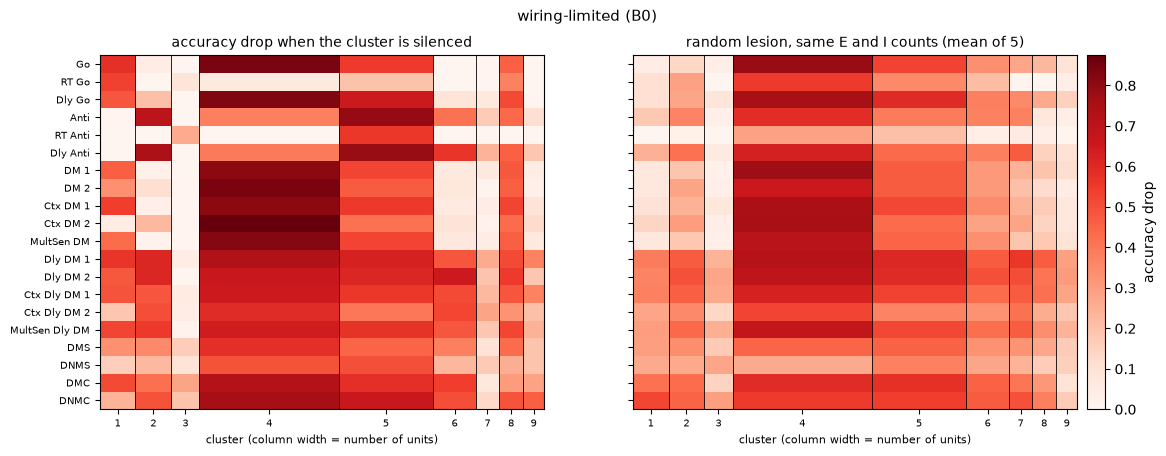

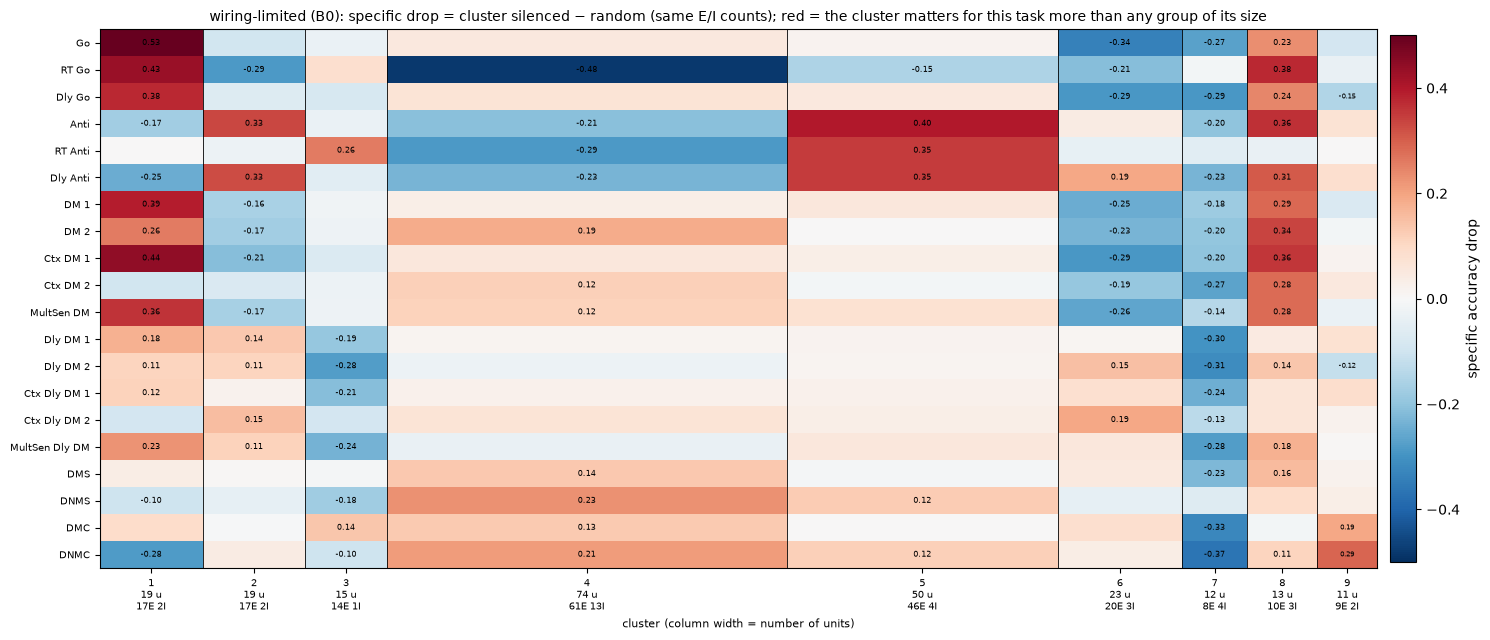

,units,E,I,mean drop,random mean drop,excess over random,max drop,worst task,max specific drop,on task,specificity
cluster,,,,,,,,,,,
1,19,17,2,0.346,0.218,0.128,0.578,Go,0.534,Go,0.232
2,19,17,2,0.318,0.322,-0.004,0.745,Dly Anti,0.334,Anti,0.427
3,15,14,1,0.063,0.123,-0.061,0.281,DMC,0.260,RT Anti,0.218
4,74,61,13,0.626,0.617,0.008,0.875,Ctx DM 2,0.229,DNMS,0.249
5,50,46,4,0.549,0.472,0.078,0.792,Anti,0.401,Anti,0.242
6,23,20,3,0.287,0.350,-0.063,0.651,Dly DM 2,0.192,Ctx Dly DM 2,0.364
7,12,8,4,0.114,0.330,-0.215,0.281,Ctx Dly DM 2,-0.012,RT Go,0.167
8,13,10,3,0.423,0.230,0.193,0.547,Dly DM 2,0.375,RT Go,0.123
9,11,9,2,0.158,0.136,0.022,0.464,DNMC,0.292,DNMC,0.305


In [5]:
R = RES["wiring-limited (B0)"]
display(R["base"].rename(index=rule_name).round(2).to_frame("intact accuracy").T)
plot_clusters(R)
plot_lesions(R)
R["summary"].round(3)

## 5. Side by side

Per network: how damaging a random group is, and how many clusters do more (or more specific) damage than a random
group of the same E/I make-up.

In [6]:
rows = []
for name, R in RES.items():
    S = R["summary"]
    rows.append({
        "network": name, "intact min acc": R["base"].min(), "k": R["K"], "silhouette": R["sil"][R["K"]],
        "mean random drop": S["random mean drop"].mean(),
        "clusters with excess > 0.1": f"{int((S['excess over random'] > 0.1).sum())}/{R['K']}",
        "clusters with a task-specific drop > 0.4": f"{int((S['max specific drop'] > 0.4).sum())}/{R['K']}",
        "their tasks": ", ".join(f"{c}: {t}" for c, t in S.loc[S["max specific drop"] > 0.4, "on task"].items()),
    })
pd.DataFrame(rows).set_index("network").round(3)

,intact min acc,k,silhouette,mean random drop,clusters with excess > 0.1,clusters with a task-specific drop > 0.4,their tasks
network,,,,,,,
control,0.943,6,0.215,0.323,2/6,3/6,"1: RT Anti, 2: RT Anti, 3: Go"
rate-limited (A0),0.776,7,0.437,0.193,0/7,1/7,2: Dly Anti
wiring-limited (B0),0.745,9,0.186,0.311,2/9,2/9,"1: Go, 5: Anti"


## Reading it

**Control (k = 6, silhouette 0.22).**
* The network is fragile: a random group (same E/I mix) of ~20% of the units already costs 0.15-0.5, mostly on the
  delay and matching tasks.
* Two small clusters act like task modules: cluster 3 (19 units) breaks Go and Dly Go (−0.7, random ≈ 0); cluster 1
  (21 units) breaks RT Anti and Dly Anti (−0.64 / −0.45).
* Cluster 2 (52 units, 18 of them I) is a hub: it breaks almost everything, more than random.
* Clusters 4-6 (46-58 units) do no more damage than random: a shared pool.

**Rate-limited A0 (k = 7, silhouette 0.44).**
* The structure is different: **one huge cluster (153 units, almost all E)** plus **six small ones (5-29 units)**.
  The high silhouette mostly comes from that split, not from many modules.
* The huge cluster is the main pool: silencing it kills every task, and so does a random group of 153 units.
* Small groups do specific jobs:
  * cluster 2 (**9 units**) breaks Anti, RT Anti and Dly Anti (−0.8 each; random ≈ 0). The cleanest module in either
    network.
  * cluster 7 (5 units, 4 I) breaks the matching tasks DNMS / DMC / DNMC (−0.3 to −0.4).
  * cluster 6 (25 units, 21 I) hurts the delay-DM tasks most (up to −0.32 over random).
* Its inhibitory units form their own small clusters (4-7 are mostly I). In the control, I units are spread over the
  big clusters.
* A random group hurts less here (mean 0.19 vs 0.32 in the control): the network is less fragile, because most
  units sit in a redundant pool.

**Wiring-limited B0 (k = 9, silhouette 0.19).**
* Fragile like the control: a random group (same E/I mix) costs 0.31 on average.
* No clean small module like A0's 9-neuron Anti group. The task-specific effects are weaker and broader:
  * cluster 1 (19 units) hurts Go most (−0.53 over random) but also the DM tasks (−0.3 to −0.4): a Go-leaning group,
    not a pure Go module.
  * cluster 5 (50 units) hurts the three Anti tasks most (−0.35 to −0.40 over random): an Anti group, but big.
  * cluster 8 (13 units) hurts nearly every task more than random (excess 0.19): a small hub.
  * the rest (including the biggest, 74 units) do no more damage than random.
* Its inhibitory units are spread over the clusters (1-4 per cluster), as in the control, not grouped as in A0.

**So:**
* **control**: a hub + two task modules (Go, Anti) + a shared pool.
* **rate-limited A0**: one big shared pool + small specialised groups (the cleanest module of all: 9 units for the
  Anti tasks), several of them inhibitory. Least fragile.
* **wiring-limited B0**: many medium clusters with broad, overlapping damage; a Go-leaning and an Anti-leaning group,
  but no clean small module. As fragile as the control.

The Anti tasks get their own group in all three networks. Clean, small, specialised groups appear under the rate
budget, not under the wiring budget.

Caveats: one network and one seed each; W_out frozen; 3 eval seeds × 64 trials; the lesion holds activity at 0.


# 6. E and I separately: what kind of modularity?

With E and I neurons there are (at least) three things a "module" could be:

1. **E modules + shared inhibition.** E neurons form task groups; I neurons belong to no group, are active in every
   task and keep everything stable (a global "volume knob").
2. **Mixed E+I modules.** Each task group has its own E *and* its own I neurons, wired mostly to each other.
3. **Inhibition between modules.** An I group belongs to one task but holds down the E neurons of *other* tasks, so
   tasks compete and the right one wins.

Three views tell them apart:

| view | type 1 | type 2 | type 3 |
|---|---|---|---|
| **task variance** (E and I clustered separately) | I neurons broad (active in many tasks), cluster poorly | I groups match an E group's tasks | I groups match tasks *other* than the E groups they connect to |
| **wiring** (I group → E group, vs shuffled groups) | even, no preference | I → E strongest between *similar* groups | I → E strongest between *dissimilar* groups |
| **lesion** (silence one I group alone, vs random I neurons) | small, unspecific | breaks the I group's *own* tasks | breaks *other* tasks |

Networks: the control (W_out frozen, 150k), L1p4 seed 3 (50k) and C0 seed 2 (150k, W_out trained) -- the two
clearest modular networks so far.

In [7]:
from scipy.stats import spearmanr

NETS_EI = {
    "control (frozen, 150k)": RUN / "control" / "seed_01.pt",
    "L1p4 s3 (50k)": MOO_ZOOM_RUNS_DIR / "dale_all_lines5_4seed_50k" / "L1p4" / "seed_03.pt",
    "C0 s2 (150k)": MOO_ZOOM_RUNS_DIR / "dale_all_woutfree_fanin_4pt_5seed_150k" / "C0" / "seed_02.pt",
}
N_SHUFFLE = 500
PRESENT = 1e-2          # a synapse is present if its E/I-normalised |w| is above this (the conn_frac threshold)


def cluster_pop(norm, k_max):
    # norm: (tasks, units) of one population, each unit divided by its own max. Local-max rule, k > 2.
    X = norm.T
    k_max = min(k_max, len(X) - 1)
    sil, labs = {}, {}
    for k in range(2, k_max + 1):
        labs[k] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)
        sil[k] = silhouette_score(X, labs[k])
    local = [k for k in range(3, k_max) if sil[k] > sil[k - 1] and sil[k] > sil[k + 1]]
    K = max(local, key=sil.get) if local else max(sil, key=sil.get)
    lab = labs[K]
    pref = {c: int(np.argmax(norm[:, lab == c].mean(axis=1))) for c in range(K)}
    order = sorted(range(K), key=lambda c: (pref[c], -norm[pref[c], lab == c].mean()))
    return np.array([order.index(c) for c in lab]), K, sil, local


def ei_study(name, ckpt):
    with contextlib.redirect_stdout(io.StringIO()):
        model, config, ck = load_checkpoint(ckpt)
    model.eval()
    tasks = list(ck["active_tasks"])
    N, N_E = model.n_rnn, model.n_e
    trials = {}
    for rule in tasks:
        for s in EVAL_SEEDS:
            cfg = eval_config_from(config, s, easy_task=True)
            tr = generate_trials(rule, cfg, BATCH, noise_on=False)
            x, _, _, y_loc = trial_to_tensors(tr, "cpu")
            trials[rule, s] = (x, y_loc, response_mask(tr, "cpu"), ring_prefs(cfg, "cpu", torch.float32))

    @torch.no_grad()
    def task_acc(keep):
        return pd.Series({rule: float(np.mean([
            batch_accuracy(simulate(model, x, keep), y_loc, prefs, resp_mask=rmask)["acc"]
            for x, y_loc, rmask, prefs in (trials[rule, s] for s in EVAL_SEEDS)])) for rule in tasks})

    base = task_acc(torch.ones(N))
    tv = np.asarray(ck["task_variance"], dtype=float)
    total = tv.sum(0)
    active = total > 1e-2 * total.max()
    normfull = tv / np.maximum(tv.max(0, keepdims=True), 1e-30)
    out = dict(name=name, tasks=tasks, base=base, N=N, N_E=N_E, normfull=normfull)
    for pop, sel, k_max in (("E", np.arange(N) < N_E, 20), ("I", np.arange(N) >= N_E, 10)):
        units = np.flatnonzero(active & sel)
        lab, K, sil, local = cluster_pop(normfull[:, units], k_max)
        prof = np.stack([normfull[:, units[lab == c]].mean(axis=1) for c in range(K)])     # (K, tasks)
        breadth = (normfull[:, units] > 0.5).sum(0)                                       # tasks per neuron
        out[pop] = dict(units=units, lab=lab, K=K, sil=sil, local=local, prof=prof, breadth=breadth,
                        sizes=np.bincount(lab, minlength=K))

    # --- wiring between I groups and E groups (mean |w|, pruned = 0), z-scored against shuffled group labels
    W = model.effective_w_rec().detach().numpy()
    scale = model.ei_row_scale().detach().numpy()[:, None]
    A = np.where(np.abs(W) / scale > PRESENT, np.abs(W), 0.0)
    E, I = out["E"], out["I"]

    def blocks(labE, labI):
        GE = np.eye(E["K"])[labE]          # (nE, KE)
        GI = np.eye(I["K"])[labI]
        A_IE = A[np.ix_(I["units"], E["units"])]
        A_EI = A[np.ix_(E["units"], I["units"])]
        nE, nI = GE.sum(0), GI.sum(0)
        return (GI.T @ A_IE @ GE) / np.outer(nI, nE), (GE.T @ A_EI @ GI) / np.outer(nE, nI)

    IE, EI = blocks(E["lab"], I["lab"])
    rng = np.random.default_rng(0)
    nulls = [blocks(rng.permutation(E["lab"]), rng.permutation(I["lab"])) for _ in range(N_SHUFFLE)]
    nIE, nEI = np.array([n[0] for n in nulls]), np.array([n[1] for n in nulls])
    out["IE_z"] = (IE - nIE.mean(0)) / np.maximum(nIE.std(0), 1e-12)          # (KI, KE)
    out["EI_z"] = (EI - nEI.mean(0)) / np.maximum(nEI.std(0), 1e-12)          # (KE, KI)
    out["sim"] = np.corrcoef(np.vstack([I["prof"], E["prof"]]))[:I["K"], I["K"]:]   # (KI, KE) task-profile r

    # --- lesions: each E group alone vs random E neurons of the same number; same for I groups
    for pop in ("E", "I"):
        P = out[pop]
        drop, rdrop = {}, {}
        for c in range(P["K"]):
            members = P["units"][P["lab"] == c]
            keep = torch.ones(N); keep[members] = 0
            drop[c + 1] = base - task_acc(keep)
            r = []
            for _ in range(N_RANDOM):
                keep = torch.ones(N); keep[rng.choice(P["units"], len(members), replace=False)] = 0
                r.append(base - task_acc(keep))
            rdrop[c + 1] = pd.concat(r, axis=1).mean(axis=1)
        P["D"] = pd.DataFrame(drop).T.rename(columns=rule_name)
        P["RD"] = pd.DataFrame(rdrop).T.rename(columns=rule_name)
        P["spec"] = P["D"] - P["RD"]
        # does silencing a group hurt its OWN tasks? r(specific drop over tasks, the group's task profile)
        P["own_r"] = np.array([spearmanr(P["spec"].values[c], P["prof"][c])[0] for c in range(P["K"])])
    print(f"{name}: E {len(E['units'])} active, k = {E['K']} (sil {E['sil'][E['K']]:.3f}); "
          f"I {len(I['units'])} active, k = {I['K']} (sil {I['sil'][I['K']]:.3f})")
    return out


def plot_ei(R):
    E, I, labels = R["E"], R["I"], [rule_name[t] for t in R["tasks"]]
    # (a) task variance of E and I separately, units grouped by their own clusters; silhouette curves
    fig = plt.figure(figsize=(20, 4.8))
    gsp = fig.add_gridspec(1, 4, width_ratios=[len(E["units"]), max(len(I["units"]), 40), 45, 45])
    cols = plt.cm.tab20(np.linspace(0, 1, 20))
    for j, (pop, P) in enumerate((("E", E), ("I", I))):
        ax = fig.add_subplot(gsp[j])
        o = np.argsort(P["lab"], kind="stable")
        ax.imshow(R["normfull"][:, P["units"][o]], cmap="hot", aspect="auto", interpolation="nearest", vmin=0, vmax=1)
        ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels if j == 0 else [], fontsize=7); ax.set_xticks([])
        labs = P["lab"][o]
        for c in range(P["K"]):
            pos = np.flatnonzero(labs == c)
            ax.plot([pos[0] - .5, pos[-1] + .5], [len(labels) + .4] * 2, lw=5, color=cols[c % 20], clip_on=False,
                    solid_capstyle="butt")
            ax.text(pos.mean(), len(labels) + 1.4, str(c + 1), ha="center", va="top", fontsize=7)
        ax.set_ylim(len(labels) - .5, -.5)
        ax.set_title(f"{pop} units ({len(P['units'])} active): k = {P['K']}, silhouette {P['sil'][P['K']]:.2f}\n"
                     f"tasks per neuron (norm. TV > 0.5): {P['breadth'].mean():.1f}", fontsize=9)
    for j, (pop, P) in enumerate((("E", E), ("I", I))):
        ax = fig.add_subplot(gsp[2 + j])
        ax.plot(list(P["sil"]), list(P["sil"].values()), "o-", ms=3)
        ax.axvline(P["K"], color="orange", ls="--", lw=1); ax.axhline(SIL_REF, color="k", ls="--", lw=1)
        ax.set_title(f"{pop}: silhouette vs k", fontsize=9); ax.set_xlabel("k")
    fig.suptitle(R["name"] + ": E and I clustered separately", fontsize=11)
    plt.tight_layout(); plt.show()

    # (b) task-profile similarity and wiring, I groups (rows) x E groups (cols)
    fig, axes = plt.subplots(1, 3, figsize=(18, 0.35 * I["K"] + 3.2))
    xl = [f"E{c + 1}\n{n}" for c, n in enumerate(E["sizes"])]
    yl = [f"I{c + 1} ({n})" for c, n in enumerate(I["sizes"])]
    for ax, M, title, lim in [(axes[0], R["sim"], "task-profile similarity (r) of I group and E group", 1),
                              (axes[1], R["IE_z"], "I → E wiring (z vs shuffled groups)", 4),
                              (axes[2], R["EI_z"].T, "E → I wiring (z vs shuffled groups)", 4)]:
        im = ax.imshow(M, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
        for (i, j), v in np.ndenumerate(M):
            if abs(v) >= (0.5 if lim == 1 else 2):
                ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6)
        ax.set_xticks(range(E["K"])); ax.set_xticklabels(xl, fontsize=6)
        ax.set_yticks(range(I["K"])); ax.set_yticklabels(yl, fontsize=7)
        ax.set_title(title, fontsize=9)
        fig.colorbar(im, ax=ax, fraction=0.03)
    fig.suptitle(R["name"] + ": do I groups pair with E groups that do the same tasks, and are they wired to them?",
                 fontsize=11)
    plt.tight_layout(); plt.show()

    # (c) specific drop (group silenced - random neurons of the same population), tasks on y, width = size
    fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw=dict(width_ratios=[2.2, 1]))
    for ax, (pop, P) in zip(axes, (("E", E), ("I", I))):
        info = pd.DataFrame({"units": P["sizes"]}, index=range(1, P["K"] + 1))
        im = lesion_panel(ax, P["spec"], info, "RdBu_r", (-0.5, 0.5),
                          f"{pop} groups silenced alone − random {pop} neurons (same number)", annotate=True)
        ax.set_xticklabels([f"{pop}{c}\n{n}" for c, n in info.units.items()], fontsize=7)
        if pop == "I":
            ax.set_yticklabels([])
    fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01, label="specific accuracy drop")
    fig.suptitle(R["name"], fontsize=11)
    plt.show()


def ei_summary(R):
    E, I = R["E"], R["I"]
    pairs_IE = spearmanr(R["sim"].ravel(), R["IE_z"].ravel())[0]
    pairs_EI = spearmanr(R["sim"].ravel(), R["EI_z"].T.ravel())[0]
    return {
        "E: tasks per neuron": E["breadth"].mean(), "I: tasks per neuron": I["breadth"].mean(),
        "E silhouette": E["sil"][E["K"]], "I silhouette": I["sil"][I["K"]],
        "best E match per I group (mean r)": R["sim"].max(axis=1).mean(),
        "I→E wiring vs similarity (ρ)": pairs_IE, "E→I wiring vs similarity (ρ)": pairs_EI,
        "I lesion hits own tasks (mean ρ)": np.nanmean(I["own_r"]),
        "E lesion hits own tasks (mean ρ)": np.nanmean(E["own_r"]),
        "I groups, mean |specific drop|": I["spec"].abs().values.mean(),
        "E groups, mean |specific drop|": E["spec"].abs().values.mean(),
    }


EI = {name: ei_study(name, ck) for name, ck in NETS_EI.items()}

control (frozen, 150k): E 196 active, k = 6 (sil 0.209); I 52 active, k = 4 (sil 0.223)


L1p4 s3 (50k): E 194 active, k = 10 (sil 0.229); I 52 active, k = 5 (sil 0.251)


C0 s2 (150k): E 176 active, k = 10 (sil 0.226); I 45 active, k = 9 (sil 0.263)


## 6.1. control (frozen, 150k)

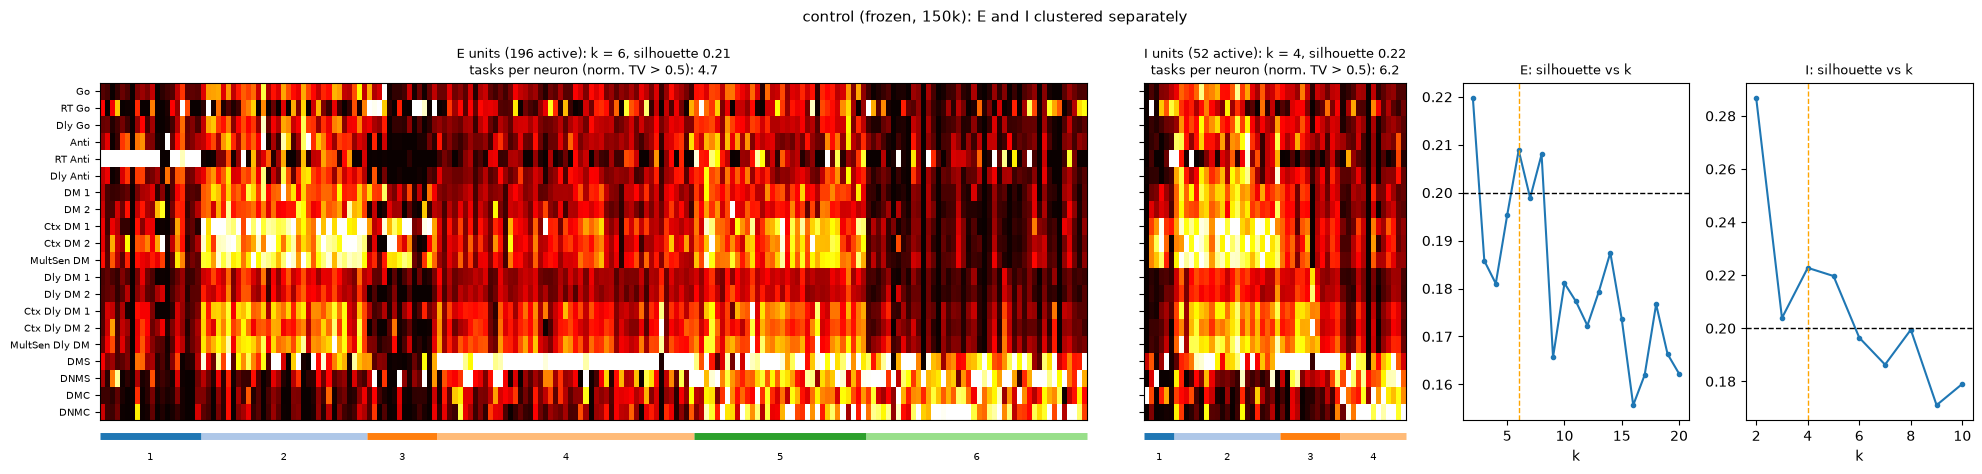

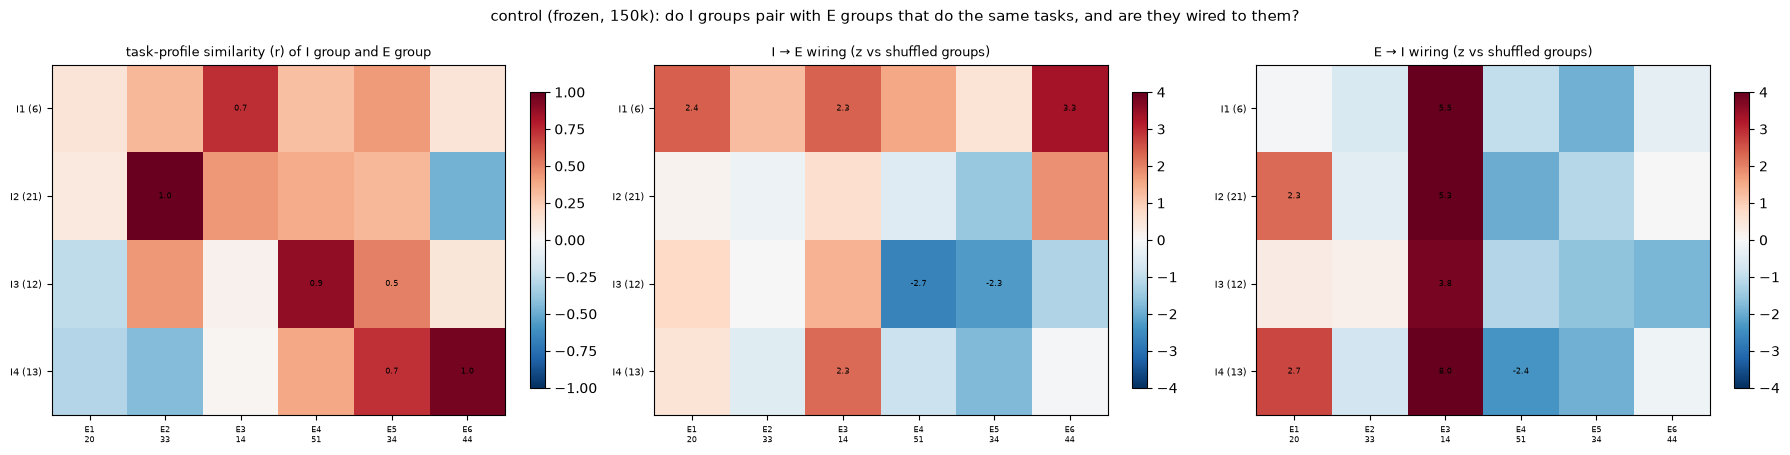

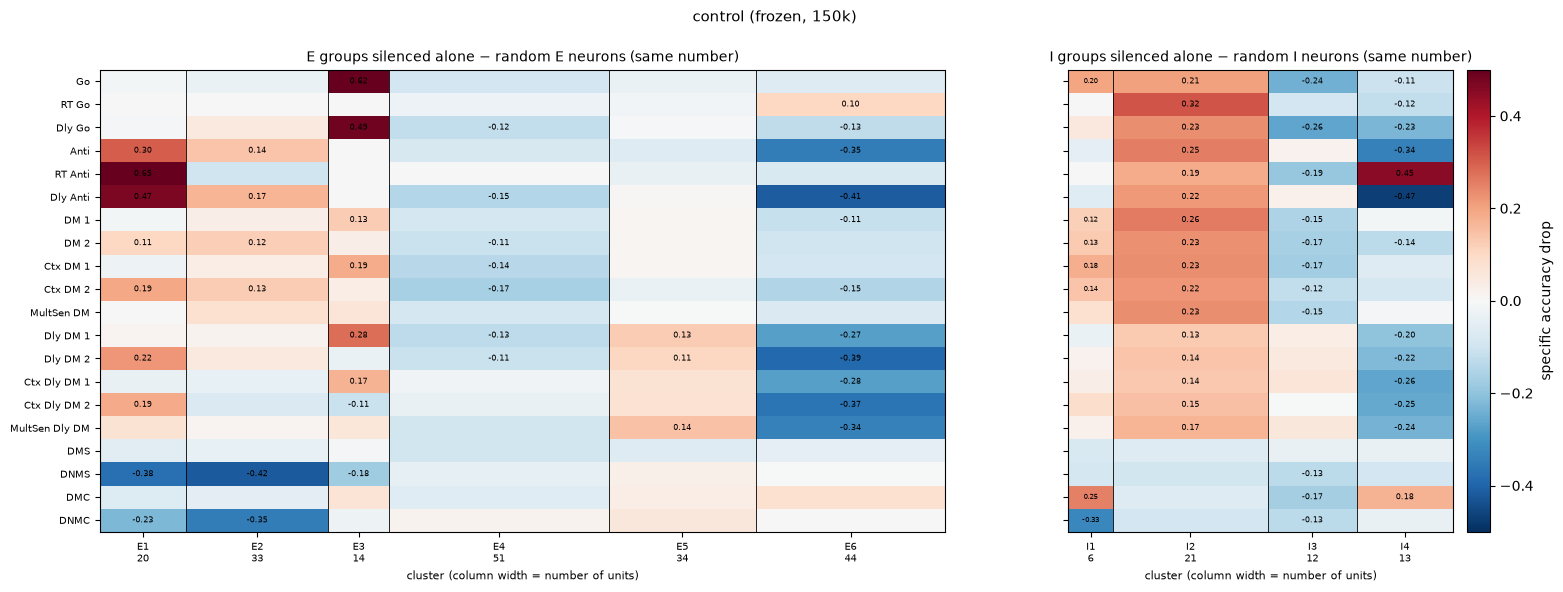

In [8]:
plot_ei(EI["control (frozen, 150k)"])

## 6.2. L1p4 s3 (50k)

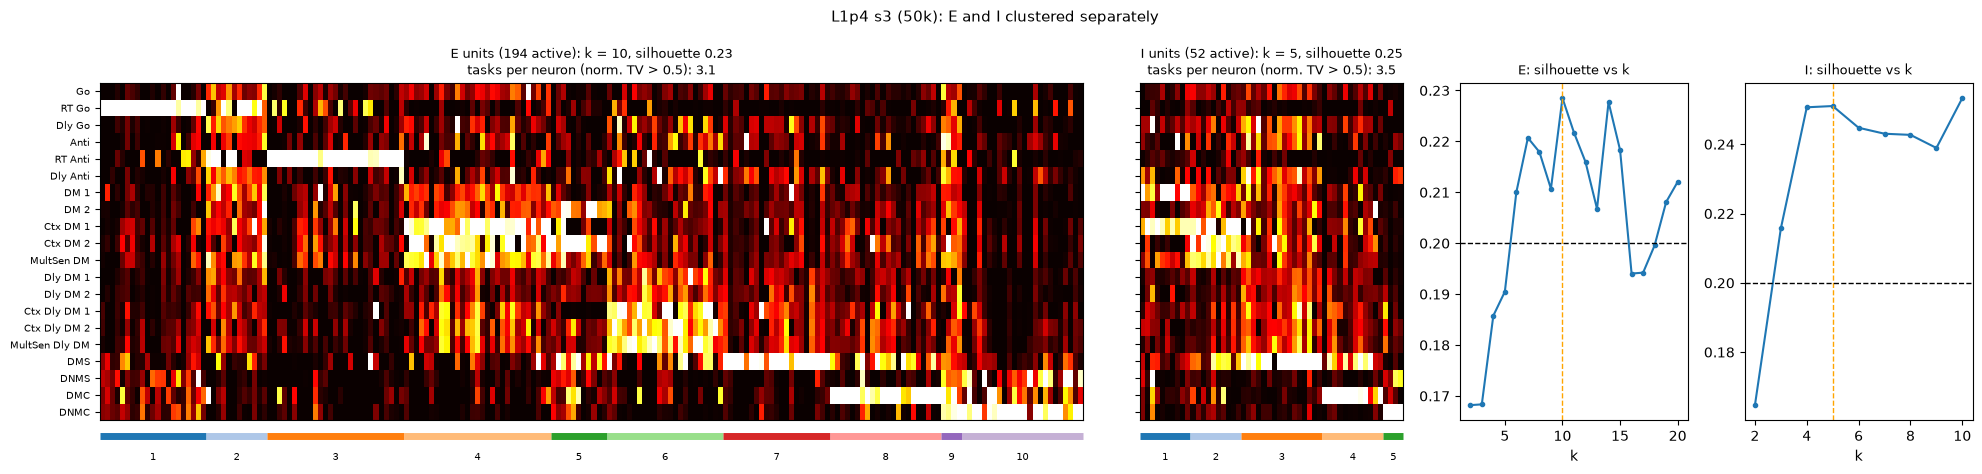

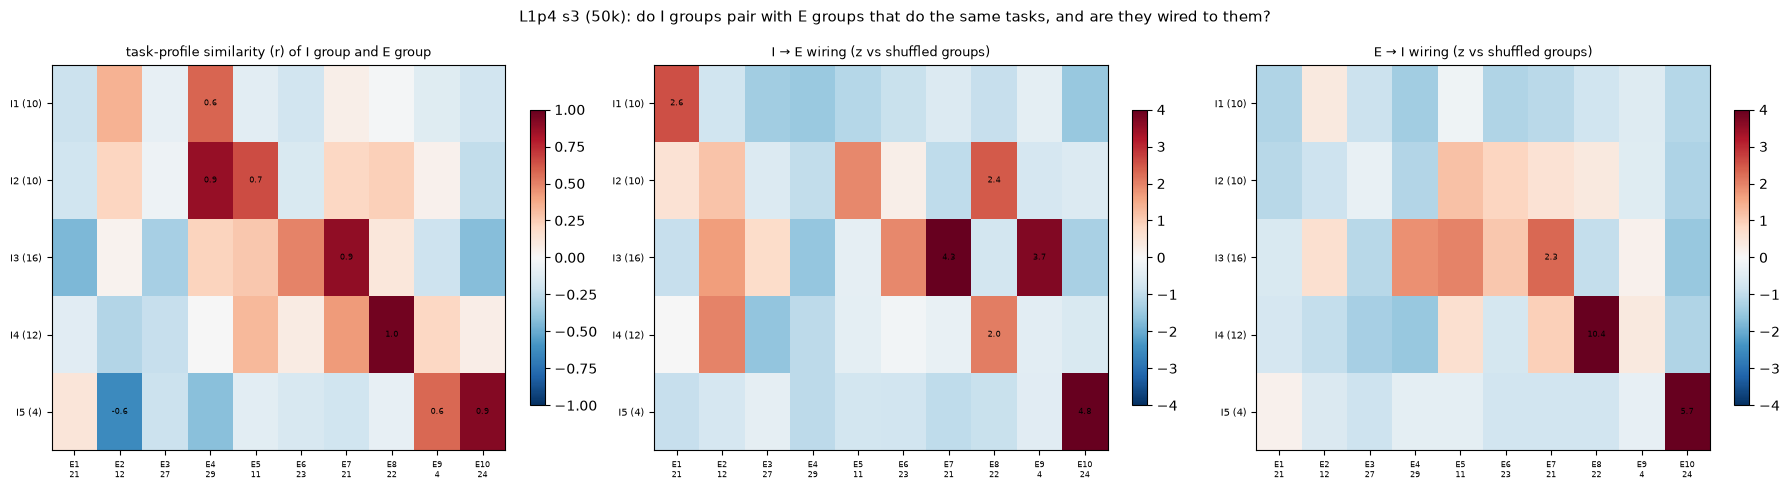

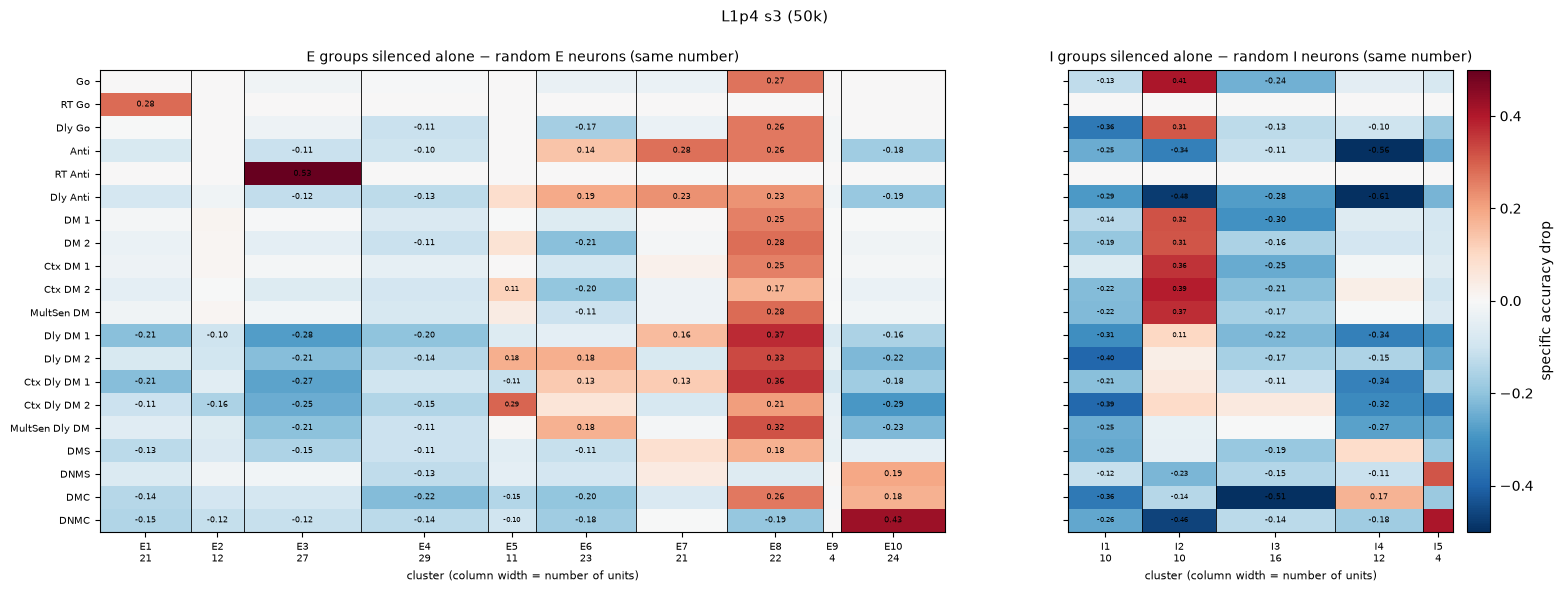

In [9]:
plot_ei(EI["L1p4 s3 (50k)"])

## 6.3. C0 s2 (150k)

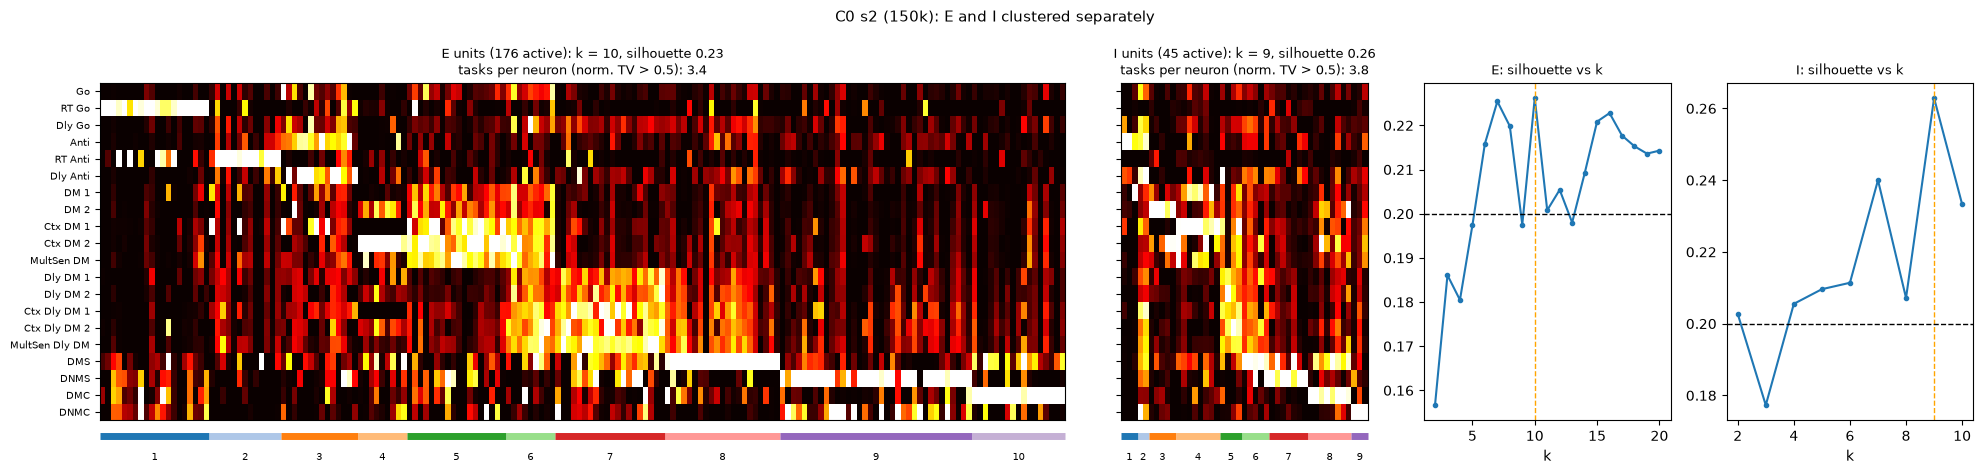

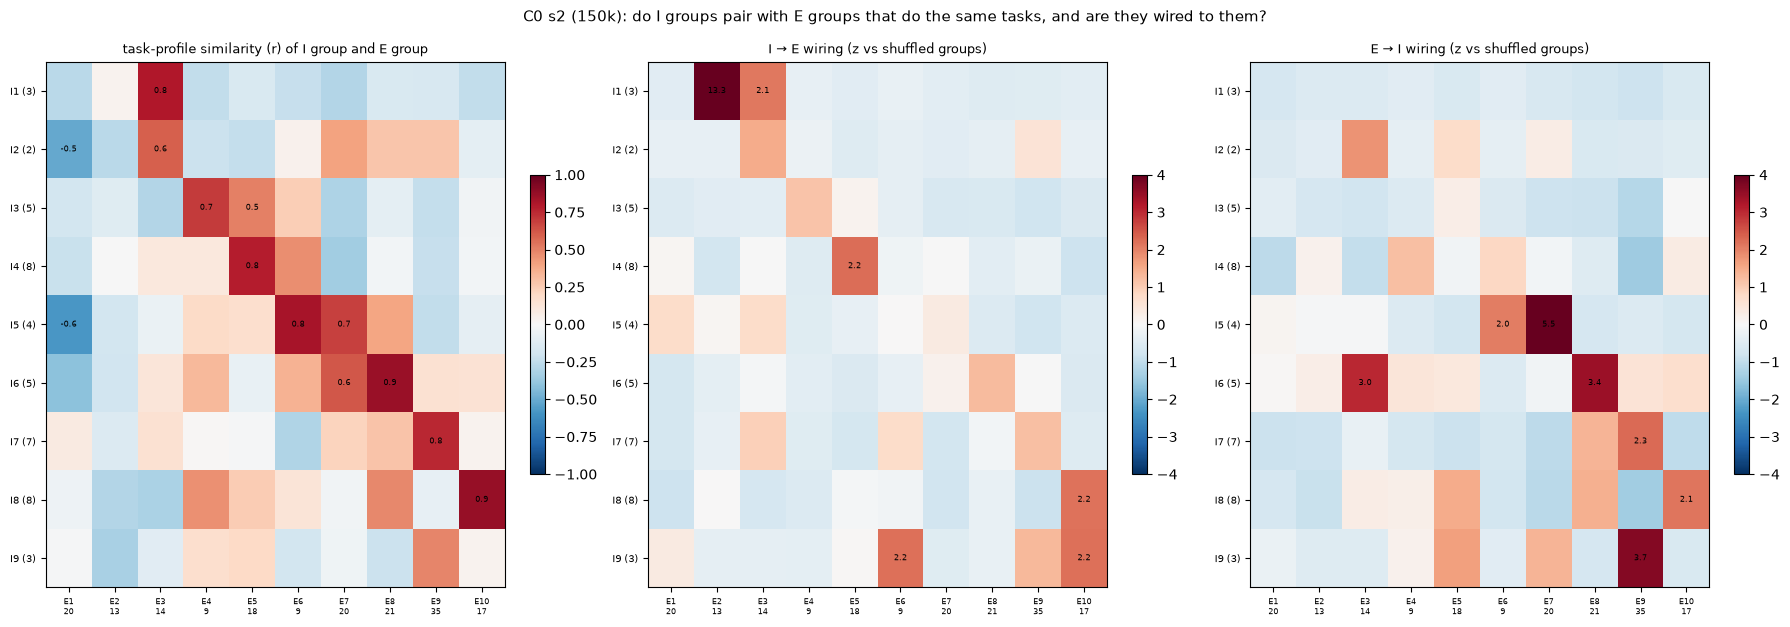

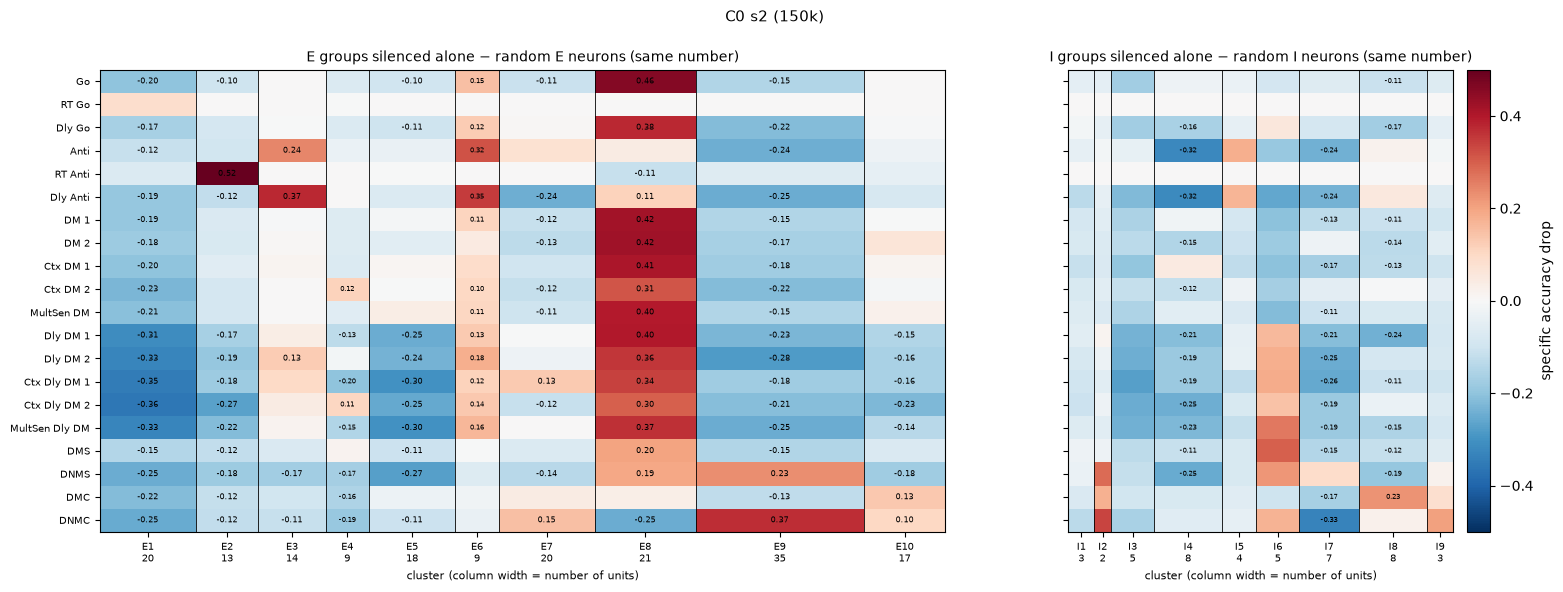

In [10]:
plot_ei(EI["C0 s2 (150k)"])

## 6.4 Side by side: which type?

* **tasks per neuron / silhouette**: broad, poorly clustered I neurons → type 1.
* **best E match per I group**: high (> ~0.7) → each I group has an E partner with the same tasks (type 2 or 3).
* **I→E wiring vs similarity**: positive → I groups connect to E groups with the *same* tasks (type 2); negative →
  to *other* tasks (type 3); about 0 → no preference (type 1).
* **I lesion hits own tasks**: positive → silencing an I group breaks its own tasks (type 2); negative → other
  tasks (type 3).

In [11]:
pd.DataFrame({name: ei_summary(R) for name, R in EI.items()}).round(3)

,"control (frozen, 150k)",L1p4 s3 (50k),C0 s2 (150k)
E: tasks per neuron,4.724,3.129,3.352
I: tasks per neuron,6.154,3.519,3.844
E silhouette,0.209,0.229,0.226
I silhouette,0.223,0.251,0.263
best E match per I group (mean r),0.895,0.845,0.742
I→E wiring vs similarity (ρ),-0.408,0.214,0.331
E→I wiring vs similarity (ρ),-0.305,0.535,0.409
I lesion hits own tasks (mean ρ),0.456,0.130,0.037
E lesion hits own tasks (mean ρ),0.307,0.352,0.214
"I groups, mean |specific drop|",0.143,0.194,0.111


## 6.5 Reading it

* **I neurons are not a shared "volume knob" in the constrained networks.** They cluster as well as the E neurons
  (silhouette 0.25-0.26 vs 0.23) and are only a little broader (3.5-3.8 tasks per neuron vs 3.1-3.4). In the control
  they are clearly broader (6.2 vs 4.7 tasks per neuron): closer to type 1.
* **Every I group has an E group with the same tasks** (best match r = 0.74-0.90 on average).
* **Wiring separates the control from the constrained networks:**
  * L1p4 and C0: I groups connect to E groups with *similar* tasks (I→E ρ +0.21 / +0.33; E→I ρ +0.54 / +0.41).
    Example, C0: I1 (3 units) → E2 (the RT Anti group), z = 13. This is **type 2: mixed E+I modules**.
  * Control: the opposite sign (ρ −0.41 / −0.31), i.e. I groups connect more to E groups of *other* tasks (type-3
    direction). But the control's wiring is dense and close to random, so its z-scores are small; read this as "no
    E+I pairing", not as strong competition.
* **Lesions do not single out I groups.** Silencing one I group alone usually hurts *less* than silencing the same
  number of random I neurons, and barely targets its own tasks (ρ 0.04-0.13 in the constrained networks). The I
  neurons in a module are wired to it, but the module still works without them (other I neurons cover).
* **So:** under the budgets, modules are **E+I modules** (type 2) by tuning and by wiring; the I part is not
  individually necessary. The control shows no such E+I pairing.

Caveats: one seed per network; L1p4 is 50k with the small W_out init, C0 and the control are 150k.
